In [2]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')


# --- 1. Read the CSV file ---
# The provided CSV file uses a semicolon (;) as a separator.
df = pd.read_csv('/content/drive/MyDrive/MScDS&AI/Gradient XGboost/student-mat.csv', sep=';')
print("--- 1. Successfully loaded 'student-mat.csv' ---")


# --- 2. Display columns and type ---
print("\n--- 2. Column Names and Data Types ---")
# Using df.info() provides a concise summary of columns and types
print(df.info())


--- 1. Successfully loaded 'student-mat.csv' ---

--- 2. Column Names and Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  a

In [3]:

# --- 3. Introduce a new column High_G3 ---
# We define 'High' as G3 > 10, and 'Moderate' otherwise
df['High_G3'] = df['G3'].apply(lambda x: 'High' if x > 10 else 'Moderate')
print("\n--- 3. New 'High_G3' column created ---")

# --- 4. Print the distribution of number of samples in High_G3 ---
print("\n--- 4. Distribution of Target Variable ('High_G3') ---")
print(df['High_G3'].value_counts())

# --- 5. Remove G3 column ---
df = df.drop('G3', axis=1)
print("\n--- 5. Original 'G3' column removed ---")

# --- 6. Prepare X by including all features except High_G3 and y as High_G3 ---
X = df.drop('High_G3', axis=1)
y = df['High_G3']
print("\n--- 6. X (features) and y (target) separated ---")

# --- 7. Convert categorical features to one-hot encoding using dummies ---
# pd.get_dummies automatically finds and converts 'object' type columns
X = pd.get_dummies(X)
print(f"\n--- 7. Features one-hot encoded. New feature count: {X.shape[1]} ---")

# (Pre-Step 8: Encode the target variable y)
# Models require numerical targets (0, 1) instead of strings ('High', 'Moderate')
le = LabelEncoder()
y = le.fit_transform(y)
# le.classes_ will store ['High', 'Moderate']
class_names = le.classes_ # Store class names for later
print(f"Target variable 'y' encoded: {list(class_names)} -> {list(range(len(class_names)))}")




--- 3. New 'High_G3' column created ---

--- 4. Distribution of Target Variable ('High_G3') ---
High_G3
High        209
Moderate    186
Name: count, dtype: int64

--- 5. Original 'G3' column removed ---

--- 6. X (features) and y (target) separated ---

--- 7. Features one-hot encoded. New feature count: 58 ---
Target variable 'y' encoded: ['High', 'Moderate'] -> [0, 1]



--- 8. Data split: 316 training samples, 79 testing samples ---

--- 9a. Fitting GradientBoostingClassifier ---

--- 9b. Fitting XGBClassifier ---

--- Evaluation for Gradient Boosting Classifier ---
Accuracy: 0.9494

Classification Report:
              precision    recall  f1-score   support

        High       0.95      0.95      0.95        42
    Moderate       0.95      0.95      0.95        37

    accuracy                           0.95        79
   macro avg       0.95      0.95      0.95        79
weighted avg       0.95      0.95      0.95        79


Confusion Matrix:
[[40  2]
 [ 2 35]]


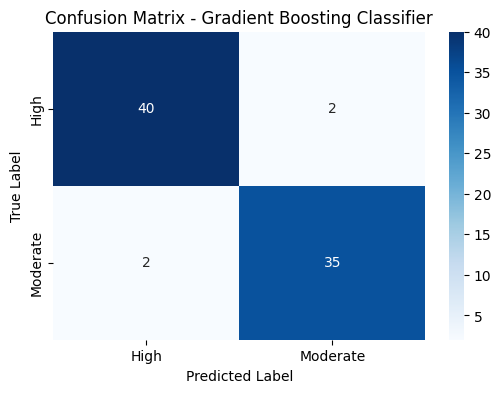


--- Evaluation for XGBoost Classifier ---
Accuracy: 0.9367

Classification Report:
              precision    recall  f1-score   support

        High       0.93      0.95      0.94        42
    Moderate       0.94      0.92      0.93        37

    accuracy                           0.94        79
   macro avg       0.94      0.94      0.94        79
weighted avg       0.94      0.94      0.94        79


Confusion Matrix:
[[40  2]
 [ 3 34]]


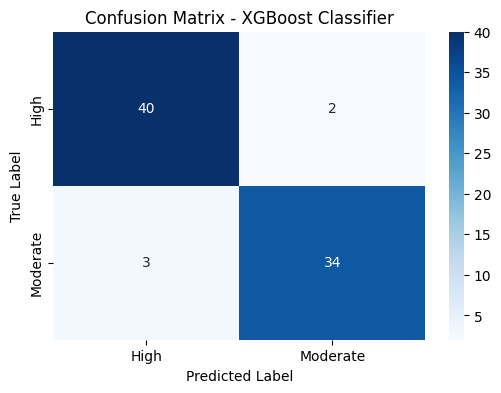


--- Analysis Complete ---


In [4]:

# --- 8. Perform train-test split of 80-20 ---
# We use stratify=y to ensure both train and test sets have a similar
# proportion of 'High' and 'Moderate' samples, which is crucial for
# classification models.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% for testing
    random_state=42,    # For reproducible results
    stratify=y          # To maintain class distribution
)
print(f"\n--- 8. Data split: {len(X_train)} training samples, {len(X_test)} testing samples ---")


# --- 9. Fit 2 models ---

# Model 1: Gradient Boost classifier
print("\n--- 9a. Fitting GradientBoostingClassifier ---")
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)

# Model 2: XGBoost classifier
print("\n--- 9b. Fitting XGBClassifier ---")
# use_label_encoder=False and eval_metric='logloss' are recommended
# for modern XGBoost versions to avoid warnings.
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

# --- 10. Evaluate Accuracy, precision, recall, f1-score, support, confusion matrix ---

# --- Evaluation for Gradient Boosting Classifier ---
print(f"\n--- Evaluation for Gradient Boosting Classifier ---")
accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Accuracy: {accuracy_gb:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, target_names=class_names))

cm_text_gb = confusion_matrix(y_test, y_pred_gb)
print("\nConfusion Matrix:")
print(cm_text_gb)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_text_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Gradient Boosting Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# --- Evaluation for XGBoost Classifier ---
print(f"\n--- Evaluation for XGBoost Classifier ---")
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"Accuracy: {accuracy_xgb:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, target_names=class_names))

cm_text_xgb = confusion_matrix(y_test, y_pred_xgb)
print("\nConfusion Matrix:")
print(cm_text_xgb)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_text_xgb, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - XGBoost Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Analysis Complete ---")

